In [1]:
from google.colab import files

uploaded = files.upload()

Saving online_retail_II.xlsx to online_retail_II.xlsx


In [2]:

import pandas as pd
import numpy as np

In [ ]:

# Get uploaded file name automatically
file_name = list(uploaded.keys())[0]

print("Uploaded File:", file_name)

# Read all Excel sheets
sheets = pd.read_excel(file_name, sheet_name=None)

# Combine all sheets into one dataset
df = pd.concat(sheets.values(), ignore_index=True)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Uploaded File: online_retail_II.xlsx


In [ ]:

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Column Names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [ ]:

print("Missing Values:")
print(df.isnull().sum())


Missing Values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [ ]:

print("Total Duplicate Rows:", df.duplicated().sum())


Total Duplicate Rows: 34335


In [ ]:

# Remove duplicate records
df = df.drop_duplicates()

# Remove missing Customer IDs
df = df.dropna(subset=['Customer ID'])

# Remove invalid transactions
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Convert Customer ID to string
df['Customer ID'] = df['Customer ID'].astype(int).astype(str)

print("Data Cleaning Completed!")
print("Cleaned Dataset Shape:", df.shape)

display(df.head())


Data Cleaning Completed!
Cleaned Dataset Shape: (779425, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


In [ ]:

df.to_csv('Cleaned_Online_Retail.csv', index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [ ]:

# Calculate total sales
df['TotalAmount'] = df['Quantity'] * df['Price']

print("Total Sales:", df['TotalAmount'].sum())
print("Total Customers:", df['Customer ID'].nunique())
print("Total Orders:", df['Invoice'].nunique())


Total Sales: 17374804.268
Total Customers: 5878
Total Orders: 36969


In [ ]:

# Set reference date one day after the last transaction
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

print("Reference Date:", snapshot_date)


Reference Date: 2011-12-10 12:50:00


In [ ]:

# Calculate RFM metrics
rfm = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'Invoice': 'nunique',
    'TotalAmount': 'sum'
})

# Rename columns
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'Invoice': 'Frequency',
    'TotalAmount': 'Monetary'
}, inplace=True)

print("RFM Table Created Successfully!")
display(rfm.head(10))


RFM Table Created Successfully!


,Recency,Frequency,Monetary
Customer ID,,,
12346,326,12,77556.46
12347,2,8,4921.53
12348,75,5,2019.40
12349,19,4,4428.69
12350,310,1,334.40
12351,375,1,300.93
12352,36,10,2849.84
12353,204,2,406.76
12354,232,1,1079.40


In [ ]:

print("RFM Summary:")
display(rfm.describe())


RFM Summary:


,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095
std,209.338707,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000


In [ ]:

rfm.to_csv('RFM_Table.csv')

print("RFM Table Saved Successfully!")


RFM Table Saved Successfully!


In [ ]:

# Calculate RFM scores

rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

display(rfm.head(10))


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
Customer ID,,,,,,
12346,326,12,77556.46,2,5,5
12347,2,8,4921.53,5,4,5
12348,75,5,2019.40,3,4,4
12349,19,4,4428.69,5,3,5
12350,310,1,334.40,2,1,2
12351,375,1,300.93,2,1,2
12352,36,10,2849.84,4,5,4
12353,204,2,406.76,2,2,2
12354,232,1,1079.40,2,1,3


In [ ]:

rfm['RFM_Score'] = (
    rfm['R_Score'] +
    rfm['F_Score'] +
    rfm['M_Score']
)

display(rfm.head(10))


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer ID,,,,,,,
12346,326,12,77556.46,2,5,5,12
12347,2,8,4921.53,5,4,5,14
12348,75,5,2019.40,3,4,4,11
12349,19,4,4428.69,5,3,5,13
12350,310,1,334.40,2,1,2,5
12351,375,1,300.93,2,1,2,5
12352,36,10,2849.84,4,5,4,13
12353,204,2,406.76,2,2,2,6
12354,232,1,1079.40,2,1,3,6


In [ ]:

def customer_segment(row):
    if row['RFM_Score'] >= 13:
        return 'Champions'
    elif row['RFM_Score'] >= 10:
        return 'Loyal Customers'
    elif row['RFM_Score'] >= 7:
        return 'Potential Loyalists'
    elif row['RFM_Score'] >= 5:
        return 'At Risk'
    else:
        return 'Lost Customers'

rfm['Customer_Segment'] = rfm.apply(
    customer_segment, axis=1
)

display(rfm.head(10))


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
Customer ID,,,,,,,,
12346,326,12,77556.46,2,5,5,12,Loyal Customers
12347,2,8,4921.53,5,4,5,14,Champions
12348,75,5,2019.40,3,4,4,11,Loyal Customers
12349,19,4,4428.69,5,3,5,13,Champions
12350,310,1,334.40,2,1,2,5,At Risk
12351,375,1,300.93,2,1,2,5,At Risk
12352,36,10,2849.84,4,5,4,13,Champions
12353,204,2,406.76,2,2,2,6,At Risk
12354,232,1,1079.40,2,1,3,6,At Risk


In [ ]:

segment_counts = rfm['Customer_Segment'].value_counts()

print("Customer Segment Distribution:")
display(segment_counts)


Customer Segment Distribution:


,count
Customer_Segment,
Potential Loyalists,1456
Loyal Customers,1356
Champions,1292
At Risk,967
Lost Customers,807


In [ ]:

rfm.to_csv('Customer_RFM_Segmentation.csv')

print("Final RFM Segmentation Saved Successfully!")


Final RFM Segmentation Saved Successfully!


In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:

# Select RFM features
X = rfm[['Recency', 'Frequency', 'Monetary']].copy()

# Apply log transformation to reduce skewness
X_log = np.log1p(X)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Data Prepared for K-Means Clustering!")
print("Scaled Data Shape:", X_scaled.shape)


Data Prepared for K-Means Clustering!
Scaled Data Shape: (5878, 3)


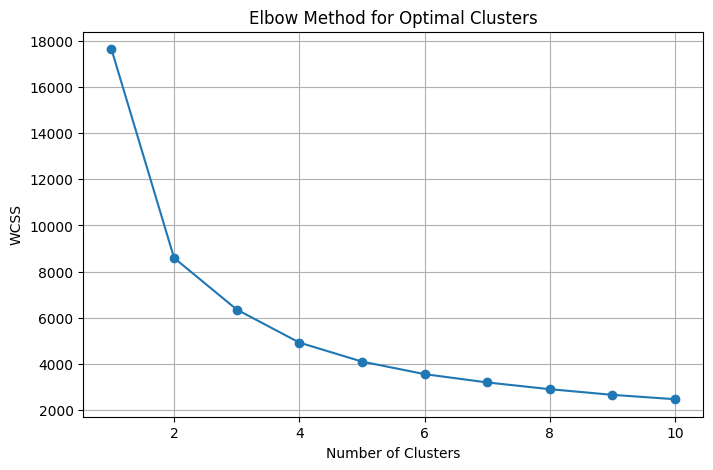

In [ ]:

wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()


In [ ]:

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed!")
display(rfm.head(10))


K-Means Clustering Completed!


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment,Cluster
Customer ID,,,,,,,,,
12346,326,12,77556.46,2,5,5,12,Loyal Customers,2
12347,2,8,4921.53,5,4,5,14,Champions,2
12348,75,5,2019.40,3,4,4,11,Loyal Customers,3
12349,19,4,4428.69,5,3,5,13,Champions,1
12350,310,1,334.40,2,1,2,5,At Risk,0
12351,375,1,300.93,2,1,2,5,At Risk,0
12352,36,10,2849.84,4,5,4,13,Champions,2
12353,204,2,406.76,2,2,2,6,At Risk,0
12354,232,1,1079.40,2,1,3,6,At Risk,0


In [ ]:
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': ['mean', 'count'],
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

# Flatten multi-index columns
cluster_summary.columns = ['Recency_Mean', 'Total_Customers', 'Frequency_Mean', 'Monetary_Mean']

display(cluster_summary)

,Recency_Mean,Total_Customers,Frequency_Mean,Monetary_Mean
Cluster,,,,
0,394.95,1973,1.38,317.08
1,28.30,1250,3.05,857.49
2,27.71,1196,19.28,10731.16
3,230.07,1459,5.06,1948.50


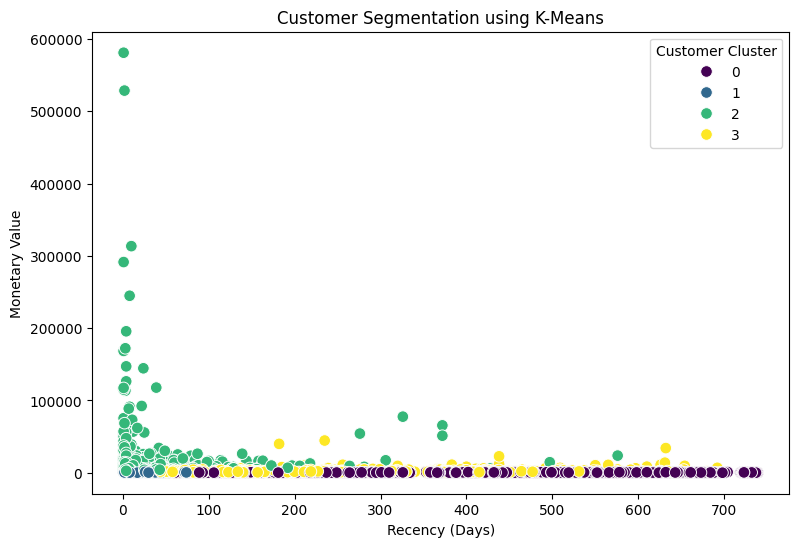

In [ ]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=70
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value')
plt.legend(title='Customer Cluster')
plt.show()


In [ ]:

rfm.to_csv('Final_Customer_Segmentation.csv')

cluster_summary.to_csv('Cluster_Summary.csv')

print("Final Customer Segmentation Saved Successfully!")


Final Customer Segmentation Saved Successfully!


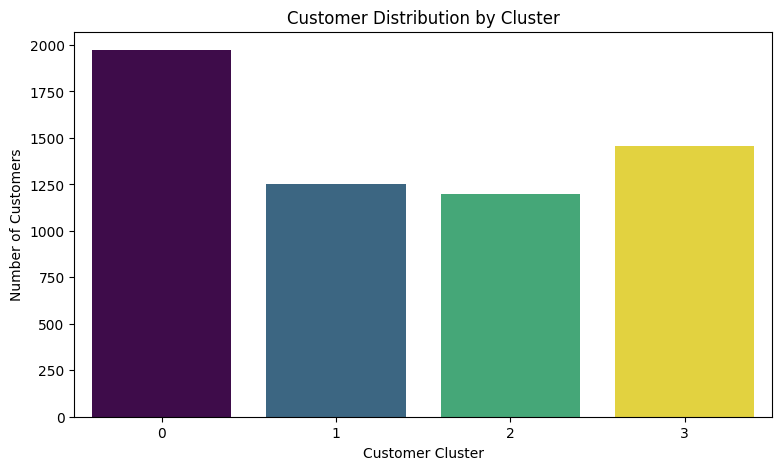

In [ ]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm,
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title('Customer Distribution by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.show()


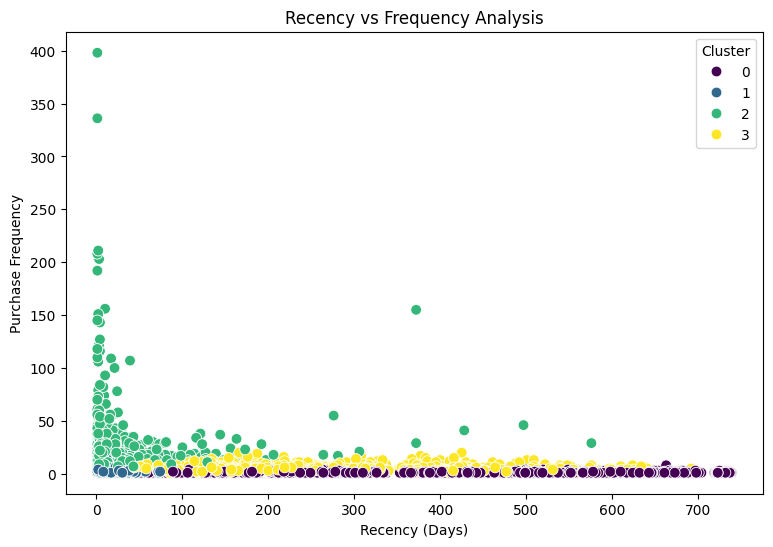

In [ ]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('Recency vs Frequency Analysis')
plt.xlabel('Recency (Days)')
plt.ylabel('Purchase Frequency')
plt.show()


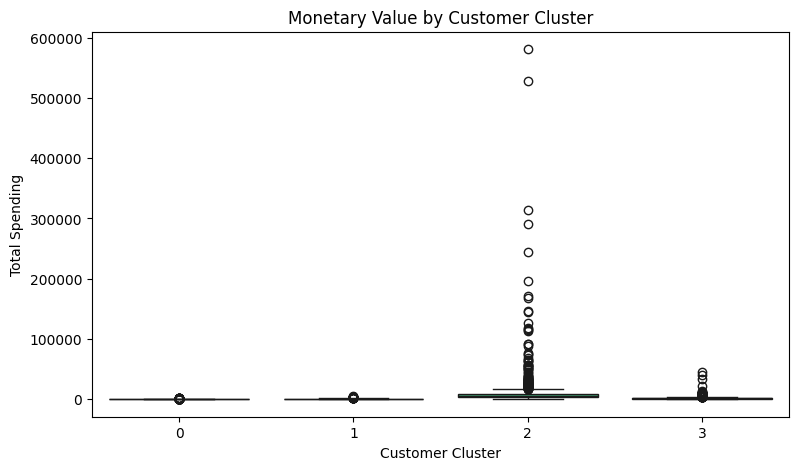

In [ ]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=rfm,
    x='Cluster',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title('Monetary Value by Customer Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Total Spending')
plt.show()


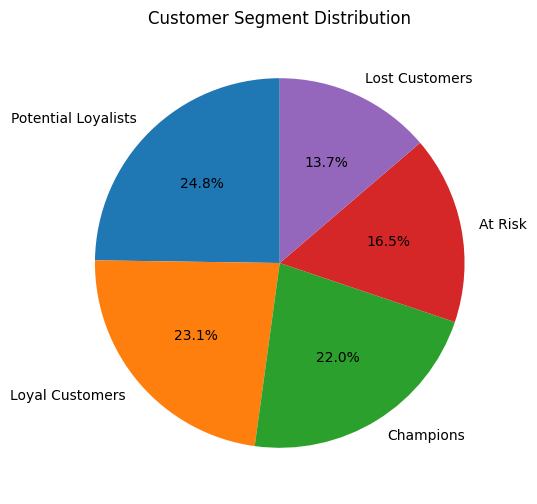

In [ ]:

plt.figure(figsize=(8, 6))

rfm['Customer_Segment'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Segment Distribution')
plt.ylabel('')
plt.show()


In [ ]:

print("CUSTOMER SEGMENT INSIGHTS")
print("=" * 40)

for segment, count in rfm['Customer_Segment'].value_counts().items():
    percentage = (count / len(rfm)) * 100

    print(f"{segment}: {count} customers ({percentage:.2f}%)")

print("\nCLUSTER PERFORMANCE")
display(cluster_summary)


CUSTOMER SEGMENT INSIGHTS
Potential Loyalists: 1456 customers (24.77%)
Loyal Customers: 1356 customers (23.07%)
Champions: 1292 customers (21.98%)
At Risk: 967 customers (16.45%)
Lost Customers: 807 customers (13.73%)

CLUSTER PERFORMANCE


,Recency_Mean,Total_Customers,Frequency_Mean,Monetary_Mean
Cluster,,,,
0,394.95,1973,1.38,317.08
1,28.30,1250,3.05,857.49
2,27.71,1196,19.28,10731.16
3,230.07,1459,5.06,1948.50


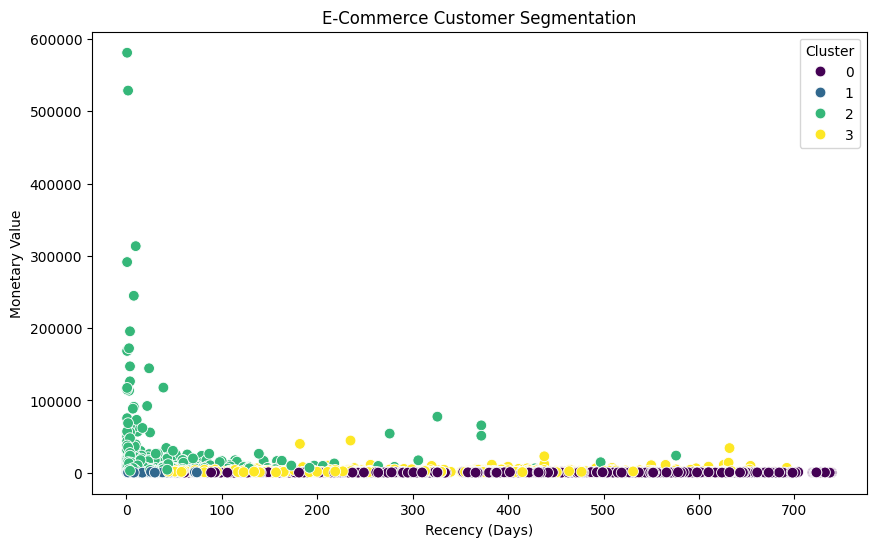

Visualization Saved Successfully!


In [ ]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('E-Commerce Customer Segmentation')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value')

plt.savefig(
    'Customer_Segmentation_Visualization.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Visualization Saved Successfully!")


In [ ]:

# Marketing recommendations

recommendations = {
    'Champions': 'Offer exclusive rewards, VIP benefits and early access to new products.',
    'Loyal Customers': 'Provide loyalty points, membership benefits and personalized offers.',
    'Potential Loyalists': 'Encourage repeat purchases through discounts and product recommendations.',
    'At Risk': 'Send re-engagement emails, special discounts and limited-time offers.',
    'Lost Customers': 'Launch win-back campaigns with attractive offers and feedback surveys.'
}

rfm['Marketing_Recommendation'] = (
    rfm['Customer_Segment'].map(recommendations)
)

display(
    rfm[['Recency', 'Frequency', 'Monetary',
         'Customer_Segment', 'Marketing_Recommendation']].head(10)
)


,Recency,Frequency,Monetary,Customer_Segment,Marketing_Recommendation
Customer ID,,,,,
12346,326,12,77556.46,Loyal Customers,"Provide loyalty points, membership benefits an..."
12347,2,8,4921.53,Champions,"Offer exclusive rewards, VIP benefits and earl..."
12348,75,5,2019.40,Loyal Customers,"Provide loyalty points, membership benefits an..."
12349,19,4,4428.69,Champions,"Offer exclusive rewards, VIP benefits and earl..."
12350,310,1,334.40,At Risk,"Send re-engagement emails, special discounts a..."
12351,375,1,300.93,At Risk,"Send re-engagement emails, special discounts a..."
12352,36,10,2849.84,Champions,"Offer exclusive rewards, VIP benefits and earl..."
12353,204,2,406.76,At Risk,"Send re-engagement emails, special discounts a..."
12354,232,1,1079.40,At Risk,"Send re-engagement emails, special discounts a..."


In [ ]:
marketing_summary = rfm.groupby('Customer_Segment').agg(
    Total_Customers=('Recency', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean')
).round(2)

marketing_summary['Recommendation'] = (
    marketing_summary.index.map(recommendations)
)

display(marketing_summary)

,Total_Customers,Average_Recency,Average_Frequency,Average_Monetary,Recommendation
Customer_Segment,,,,,
At Risk,967,320.68,1.41,386.23,"Send re-engagement emails, special discounts a..."
Champions,1292,25.74,17.98,9694.38,"Offer exclusive rewards, VIP benefits and earl..."
Lost Customers,807,516.81,1.06,196.54,Launch win-back campaigns with attractive offe...
Loyal Customers,1356,95.74,5.58,2268.68,"Provide loyalty points, membership benefits an..."
Potential Loyalists,1456,201.37,2.71,852.50,Encourage repeat purchases through discounts a...


In [ ]:

with pd.ExcelWriter('Customer_RFM_Marketing_Analysis.xlsx') as writer:

    rfm.to_excel(writer, sheet_name='Customer Segments')

    marketing_summary.to_excel(
        writer,
        sheet_name='Marketing Summary'
    )

    cluster_summary.to_excel(
        writer,
        sheet_name='Cluster Summary'
    )

print("Excel Report Created Successfully!")


Excel Report Created Successfully!


In [ ]:

from google.colab import files

files.download('Customer_RFM_Marketing_Analysis.xlsx')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Export final customer segmentation dataset
rfm.to_csv('Final_Customer_RFM.csv', index=False)

from google.colab import files
files.download('Final_Customer_RFM.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>